# Setup check

<p class="lead">
Run this notebook once on your own computer before Day 1. It checks that Python, every package the course needs and every data file are ready, without using the internet.
</p>

---

## How to use it

1. Keep this notebook in the course folder, next to the `data` folder. Do not move it on its own.
2. Choose **Run → Run All Cells** (or **Kernel → Restart Kernel and Run All Cells**).
3. Read each line of output:

| You see | Meaning | What to do |
|---|---|---|
| `OK` | This part works | Nothing |
| `MISSING` | A package or file is not there | Follow the fix shown on the same line |
| `PROBLEM` | Something is there but does not work as expected | Show the line to your facilitator |

4. Scroll to the **Summary** at the bottom. It says either **All checks passed** or lists what to fix.

> **Nothing here changes your computer**
>
> The checks only read files and print results. The one exception is the NLTK step, which unpacks a small tokenizer file inside `data/nltk_data` the first time it runs. That is expected.

---

## 1. Python version

The course needs Python 3.10 or newer. A current Anaconda Distribution gives you this.

In [1]:
import sys

problems = []  # every check below adds to this list if something is wrong

version = sys.version_info
print(f"Python {version.major}.{version.minor}.{version.micro}")
if version >= (3, 10):
    print("OK       Python is 3.10 or newer")
else:
    print("PROBLEM  Python is older than 3.10. Fix: install a current Anaconda Distribution")
    problems.append("Python is older than 3.10")

Python 3.12.13
OK       Python is 3.10 or newer


---

## 2. Packages

Each package is tried on its own, so one missing package never stops the others from being checked. All of them come with Anaconda except `wordcloud`, which you install once (see the Setup page).

In [2]:
import importlib

# (name used in import, name shown, how to fix it if missing)
PACKAGES = [
    ("numpy", "numpy", "conda install numpy"),
    ("pandas", "pandas", "conda install pandas"),
    ("matplotlib", "matplotlib", "conda install matplotlib"),
    ("seaborn", "seaborn", "conda install seaborn"),
    ("statsmodels", "statsmodels", "conda install statsmodels"),
    ("sklearn", "scikit-learn", "conda install scikit-learn"),
    ("nltk", "nltk", "conda install nltk"),
    ("wordcloud", "wordcloud", "pip install wordcloud  (in Anaconda Prompt or Terminal)"),
]

available = {}
for module_name, shown, fix in PACKAGES:
    try:
        module = importlib.import_module(module_name)
        available[shown] = True
        print(f"OK       {shown:<13} version {module.__version__}")
    except Exception:
        available[shown] = False
        print(f"MISSING  {shown:<13} Fix: {fix}")
        problems.append(f"{shown} is missing. Fix: {fix}")

OK       numpy         version 2.5.4
OK       pandas        version 2.2.3
OK       matplotlib    version 3.11.2
OK       seaborn       version 0.13.2
OK       statsmodels   version 0.15.0
OK       scikit-learn  version 1.9.1
OK       nltk          version 3.10.3
OK       wordcloud     version 1.9.6


---

## 3. Data files

Every dataset the course uses is in the `data` folder. Each file is loaded and its size (rows × columns) compared with what the course expects.

In [3]:
from pathlib import Path

DATA = Path("data")

EXPECTED_SHAPES = {
    "penguins.csv": (344, 7),
    "diamonds.csv": (53940, 10),
    "tips.csv": (244, 7),
    "mpg.csv": (398, 9),
    "datasaurus_dozen.csv": (1846, 3),
}

NLTK_FILES = [
    "nltk_data/sentiment/vader_lexicon.zip",
    "nltk_data/corpora/stopwords.zip",
    "nltk_data/tokenizers/punkt_tab.zip",
]

if not DATA.is_dir():
    print("MISSING  the data folder. Fix: open this notebook from inside the course folder, next to 'data'")
    problems.append("The data folder is not next to this notebook")
else:
    for name, expected in EXPECTED_SHAPES.items():
        path = DATA / name
        if not path.exists():
            print(f"MISSING  {name}. Fix: copy the course folder again from your facilitator")
            problems.append(f"{name} is missing")
            continue
        if not available.get("pandas"):
            print(f"PROBLEM  {name} exists but cannot be loaded without pandas")
            problems.append(f"{name} not loaded (pandas missing)")
            continue
        import pandas as pd

        try:
            found = pd.read_csv(path).shape
        except Exception as error:
            print(f"PROBLEM  {name} could not be read: {error}")
            problems.append(f"{name} could not be read")
            continue
        if found == expected:
            print(f"OK       {name:<22} {found[0]:>6} rows x {found[1]} columns")
        else:
            print(f"PROBLEM  {name}: expected {expected}, found {found}. Fix: copy the file again")
            problems.append(f"{name} has the wrong shape")

    for name in NLTK_FILES:
        if (DATA / name).exists():
            print(f"OK       {name}")
        else:
            print(f"MISSING  {name}. Fix: copy the course folder again from your facilitator")
            problems.append(f"{name} is missing")

OK       penguins.csv              344 rows x 7 columns
OK       diamonds.csv            53940 rows x 10 columns
OK       tips.csv                  244 rows x 7 columns
OK       mpg.csv                   398 rows x 9 columns
OK       datasaurus_dozen.csv     1846 rows x 3 columns
OK       nltk_data/sentiment/vader_lexicon.zip
OK       nltk_data/corpora/stopwords.zip
OK       nltk_data/tokenizers/punkt_tab.zip


---

## 4. Text tools (NLTK), offline

The text-mining lab uses NLTK with word lists stored in `data/nltk_data`, so nothing is downloaded. The cell below is the same setup the labs use, wrapped in a check so that a problem is reported instead of stopping the notebook.

In [4]:
nltk_ready = False
try:
    import zipfile
    from pathlib import Path

    import nltk

    NLTK_DIR = Path("data/nltk_data").resolve()
    if not (NLTK_DIR / "tokenizers" / "punkt_tab").exists():
        with zipfile.ZipFile(NLTK_DIR / "tokenizers" / "punkt_tab.zip") as z:
            z.extractall(NLTK_DIR / "tokenizers")
    nltk.data.path.insert(0, str(NLTK_DIR))

    nltk_ready = True
    print("OK       NLTK is set up to use the course word lists")
except Exception as error:
    print(f"PROBLEM  NLTK setup failed ({type(error).__name__}). Check that nltk is installed and the data folder is complete")
    problems.append("NLTK setup failed")

OK       NLTK is set up to use the course word lists


Now three quick tests: split a sentence into words (tokenise), load the English stop-word list, and score the sentiment of two short reviews with VADER.

In [5]:
sentence = "The delivery was late, but the staff were great!"

if not nltk_ready:
    print("PROBLEM  NLTK tests skipped because the setup above failed")
else:
    try:
        from nltk.tokenize import word_tokenize

        print("OK       tokenise:", word_tokenize(sentence))
    except Exception as error:
        print(f"PROBLEM  tokenise failed ({type(error).__name__})")
        problems.append("NLTK tokeniser does not work")

    try:
        from nltk.corpus import stopwords

        english = stopwords.words("english")
        print(f"OK       stop words: {len(english)} English words, for example {english[:5]}")
    except Exception as error:
        print(f"PROBLEM  stop words failed ({type(error).__name__})")
        problems.append("NLTK stop words do not load")

    try:
        from nltk.sentiment import SentimentIntensityAnalyzer

        vader = SentimentIntensityAnalyzer()
        for review in ["Excellent service, I loved it.", "Terrible food and a rude waiter."]:
            score = vader.polarity_scores(review)["compound"]
            print(f"OK       VADER: {score:+.3f}  {review}")
    except Exception as error:
        print(f"PROBLEM  VADER failed ({type(error).__name__})")
        problems.append("VADER sentiment lexicon does not load")

OK       tokenise: ['The', 'delivery', 'was', 'late', ',', 'but', 'the', 'staff', 'were', 'great', '!']
OK       stop words: 198 English words, for example ['a', 'about', 'above', 'after', 'again']
OK       VADER: +0.823  Excellent service, I loved it.
OK       VADER: -0.727  Terrible food and a rude waiter.


The first review should score above zero (positive) and the second below zero (negative).

---

## 5. The CO₂ time series

The forecasting lab uses a CO₂ series that ships inside `statsmodels`, so it also works offline.

In [6]:
try:
    import statsmodels.api as sm

    co2 = sm.datasets.co2.load_pandas().data
    print(f"OK       CO2 series: {len(co2)} weekly readings, "
          f"{co2.index.min().date()} to {co2.index.max().date()}")
except Exception as error:
    print(f"PROBLEM  CO2 series did not load ({type(error).__name__}). Fix: conda install statsmodels")
    problems.append("statsmodels CO2 data does not load")

OK       CO2 series: 2284 weekly readings, 1958-03-29 to 2001-12-29


---

## 6. A test chart

If you can see a small bar chart below this cell, charts work.

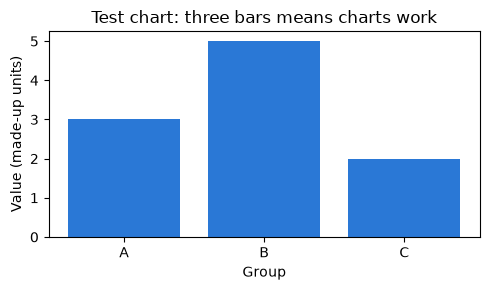

In [7]:
try:
    import matplotlib.pyplot as plt

    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(["A", "B", "C"], [3, 5, 2], color="#2a78d6")
    ax.set_title("Test chart: three bars means charts work")
    ax.set_xlabel("Group")
    ax.set_ylabel("Value (made-up units)")
    fig.tight_layout()
    plt.show()
except Exception as error:
    print(f"PROBLEM  the test chart failed ({type(error).__name__}). Fix: conda install matplotlib")
    problems.append("matplotlib cannot draw a chart")

---

## Summary

In [8]:
if not problems:
    print("All checks passed. Your computer is ready for the course.")
else:
    print(f"{len(problems)} problem(s) found. Fix them, then run this notebook again:")
    for number, problem in enumerate(problems, start=1):
        print(f"  {number}. {problem}")

All checks passed. Your computer is ready for the course.


> **If something is still wrong**
>
> Take a screenshot of the output above and show it to your facilitator before Day 1. Most problems are fixed by installing one package or by opening the notebook from inside the course folder.